In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Project environment is ready!")

Project environment is ready!


In [3]:
import pandas as pd

file_path = "../data/train_FD001.txt"

df = pd.read_csv(file_path, sep=r"\s+", header=None)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (20631, 26)


,0,1,2,3,4,5,6,7,8,9,...,16,17,18,19,20,21,22,23,24,25
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [4]:
columns = [
    "engine_id",
    "cycle",
    "setting_1",
    "setting_2",
    "setting_3",
    "sensor_1",
    "sensor_2",
    "sensor_3",
    "sensor_4",
    "sensor_5",
    "sensor_6",
    "sensor_7",
    "sensor_8",
    "sensor_9",
    "sensor_10",
    "sensor_11",
    "sensor_12",
    "sensor_13",
    "sensor_14",
    "sensor_15",
    "sensor_16",
    "sensor_17",
    "sensor_18",
    "sensor_19",
    "sensor_20",
    "sensor_21"
]

df.columns = columns

print("Column names added successfully!")
print(df.shape)
df.head()

Column names added successfully!
(20631, 26)


,engine_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [5]:
missing = df.isnull().sum()

print("Missing values:")
print(missing[missing > 0])

print("\nTotal missing values:", df.isnull().sum().sum())

Missing values:
Series([], dtype: int64)

Total missing values: 0


In [6]:
print("Number of engines:", df["engine_id"].nunique())

print("\nCycles per engine:")
print(df.groupby("engine_id")["cycle"].max().describe())

Number of engines: 100

Cycles per engine:
count    100.000000
mean     206.310000
std       46.342749
min      128.000000
25%      177.000000
50%      199.000000
75%      229.250000
max      362.000000
Name: cycle, dtype: float64


In [7]:
df["RUL"] = df.groupby("engine_id")["cycle"].transform("max") - df["cycle"]

print("RUL created successfully!")

print("\nRUL summary:")
print(df["RUL"].describe())

print("\nSample data:")
print(df[["engine_id", "cycle", "RUL"]].head(10))

RUL created successfully!

RUL summary:
count    20631.000000
mean       107.807862
std         68.880990
min          0.000000
25%         51.000000
50%        103.000000
75%        155.000000
max        361.000000
Name: RUL, dtype: float64

Sample data:
   engine_id  cycle  RUL
0          1      1  191
1          1      2  190
2          1      3  189
3          1      4  188
4          1      5  187
5          1      6  186
6          1      7  185
7          1      8  184
8          1      9  183
9          1     10  182


In [8]:
sensor_cols = [col for col in df.columns if col.startswith("sensor_")]

sensor_stats = df[sensor_cols].agg(["mean", "std", "min", "max"]).T

print("Sensor statistics:")
print(sensor_stats)

Sensor statistics:
                  mean           std        min        max
sensor_1    518.670000  0.000000e+00   518.6700   518.6700
sensor_2    642.680934  5.000533e-01   641.2100   644.5300
sensor_3   1590.523119  6.131150e+00  1571.0400  1616.9100
sensor_4   1408.933782  9.000605e+00  1382.2500  1441.4900
sensor_5     14.620000  5.329200e-15    14.6200    14.6200
sensor_6     21.609803  1.388985e-03    21.6000    21.6100
sensor_7    553.367711  8.850923e-01   549.8500   556.0600
sensor_8   2388.096652  7.098548e-02  2387.9000  2388.5600
sensor_9   9065.242941  2.208288e+01  9021.7300  9244.5900
sensor_10     1.300000  0.000000e+00     1.3000     1.3000
sensor_11    47.541168  2.670874e-01    46.8500    48.5300
sensor_12   521.413470  7.375534e-01   518.6900   523.3800
sensor_13  2388.096152  7.191892e-02  2387.8800  2388.5600
sensor_14  8143.752722  1.907618e+01  8099.9400  8293.7200
sensor_15     8.442146  3.750504e-02     8.3249     8.5848
sensor_16     0.030000  3.469531e-18 

In [9]:
constant_sensors = [
    col for col in sensor_cols
    if df[col].nunique() <= 1
]

print("Constant sensors:")
print(constant_sensors)

print("\nNumber of constant sensors:", len(constant_sensors))

Constant sensors:
['sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']

Number of constant sensors: 6


In [10]:
# Remove constant sensors from the feature list
useful_sensors = [
    col for col in sensor_cols
    if col not in constant_sensors
]

print("Original number of sensors:", len(sensor_cols))
print("Constant sensors removed:", len(constant_sensors))
print("Remaining sensors:", len(useful_sensors))

print("\nRemaining sensors:")
print(useful_sensors)

Original number of sensors: 21
Constant sensors removed: 6
Remaining sensors: 15

Remaining sensors:
['sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


In [11]:
# Correlation of each useful sensor with RUL
correlations = df[useful_sensors + ["RUL"]].corr()["RUL"].drop("RUL")

# Sort by absolute correlation
correlation_table = correlations.abs().sort_values(ascending=False).to_frame(
    name="absolute_correlation"
)

# Add the actual correlation value
correlation_table["correlation"] = correlations[correlation_table.index]

print("Sensor correlation with RUL:")
print(correlation_table)

Sensor correlation with RUL:
           absolute_correlation  correlation
sensor_11              0.696228    -0.696228
sensor_4               0.678948    -0.678948
sensor_12              0.671983     0.671983
sensor_7               0.657223     0.657223
sensor_15              0.642667    -0.642667
sensor_21              0.635662     0.635662
sensor_20              0.629428     0.629428
sensor_2               0.606484    -0.606484
sensor_17              0.606154    -0.606154
sensor_3               0.584520    -0.584520
sensor_8               0.563968    -0.563968
sensor_13              0.562569    -0.562569
sensor_9               0.390102    -0.390102
sensor_14              0.306769    -0.306769
sensor_6               0.128348    -0.128348


In [12]:
# Select sensors with meaningful correlation to RUL
correlation_threshold = 0.50

selected_sensors = correlation_table[
    correlation_table["absolute_correlation"] >= correlation_threshold
].index.tolist()

print("Selected sensors:")
print(selected_sensors)

print("\nNumber of selected sensors:", len(selected_sensors))

Selected sensors:
['sensor_11', 'sensor_4', 'sensor_12', 'sensor_7', 'sensor_15', 'sensor_21', 'sensor_20', 'sensor_2', 'sensor_17', 'sensor_3', 'sensor_8', 'sensor_13']

Number of selected sensors: 12


In [13]:
# Select sensors with meaningful correlation to RUL
correlation_threshold = 0.50

selected_sensors = correlation_table[
    correlation_table["absolute_correlation"] >= correlation_threshold
].index.tolist()

print("Selected sensors:")
print(selected_sensors)

print("\nNumber of selected sensors:", len(selected_sensors))

Selected sensors:
['sensor_11', 'sensor_4', 'sensor_12', 'sensor_7', 'sensor_15', 'sensor_21', 'sensor_20', 'sensor_2', 'sensor_17', 'sensor_3', 'sensor_8', 'sensor_13']

Number of selected sensors: 12


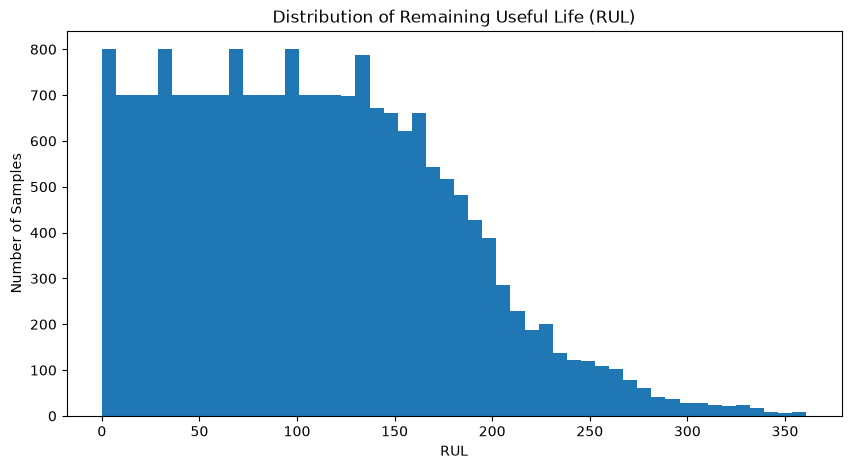

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(df["RUL"], bins=50)

plt.xlabel("RUL")
plt.ylabel("Number of Samples")
plt.title("Distribution of Remaining Useful Life (RUL)")

plt.show()

In [15]:
# Create feature matrix and target

X = df[selected_sensors]
y = df["RUL"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nSelected features:")
print(selected_sensors)

Features shape: (20631, 12)
Target shape: (20631,)

Selected features:
['sensor_11', 'sensor_4', 'sensor_12', 'sensor_7', 'sensor_15', 'sensor_21', 'sensor_20', 'sensor_2', 'sensor_17', 'sensor_3', 'sensor_8', 'sensor_13']


In [16]:
# Split data by engine to avoid data leakage

from sklearn.model_selection import train_test_split

engine_ids = df["engine_id"].unique()

train_engines, test_engines = train_test_split(
    engine_ids,
    test_size=0.2,
    random_state=42
)

train_df = df[df["engine_id"].isin(train_engines)].copy()
test_df = df[df["engine_id"].isin(test_engines)].copy()

X_train = train_df[selected_sensors]
y_train = train_df["RUL"]

X_test = test_df[selected_sensors]
y_test = test_df["RUL"]

print("Training engines:", len(train_engines))
print("Testing engines:", len(test_engines))

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

Training engines: 80
Testing engines: 20
X_train: (16561, 12)
X_test: (4070, 12)


In [17]:
# Train Random Forest model

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [18]:
# Make predictions

y_pred = model.predict(X_test)

print("Predictions completed!")
print("First 10 predictions:")
print(y_pred[:10])

Predictions completed!
First 10 predictions:
[153.39  159.11  164.51  178.76  136.33  152.06  154.23  145.63  166.835
 160.455]


In [19]:
# Evaluate model performance

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Model Performance")
print("-----------------")
print("MAE :", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R²  :", round(r2, 4))

Model Performance
-----------------
MAE : 29.57
RMSE: 39.07
R²  : 0.6458


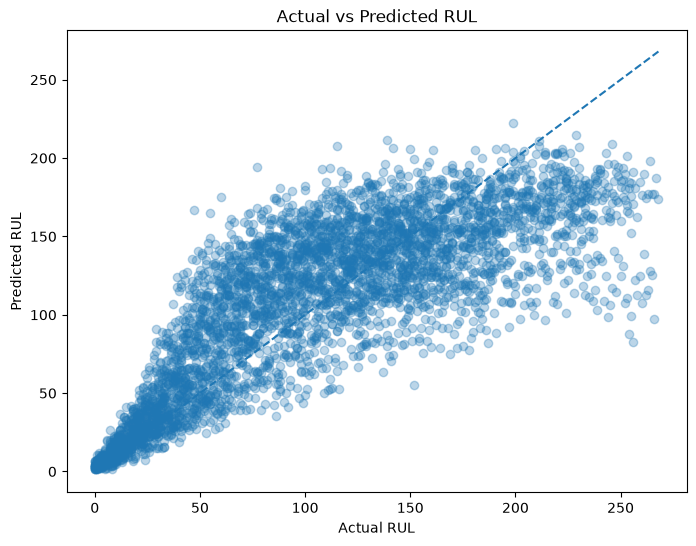

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.3)

plt.xlabel("Actual RUL")
plt.ylabel("Predicted RUL")
plt.title("Actual vs Predicted RUL")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.show()

In [21]:
# Feature importance

feature_importance = pd.DataFrame({
    "sensor": selected_sensors,
    "importance": model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "importance",
    ascending=False
)

print(feature_importance)

       sensor  importance
0   sensor_11    0.455783
1    sensor_4    0.109382
4   sensor_15    0.057927
5   sensor_21    0.055425
9    sensor_3    0.052236
3    sensor_7    0.051102
2   sensor_12    0.048396
7    sensor_2    0.046763
6   sensor_20    0.040508
11  sensor_13    0.032124
10   sensor_8    0.032087
8   sensor_17    0.018270


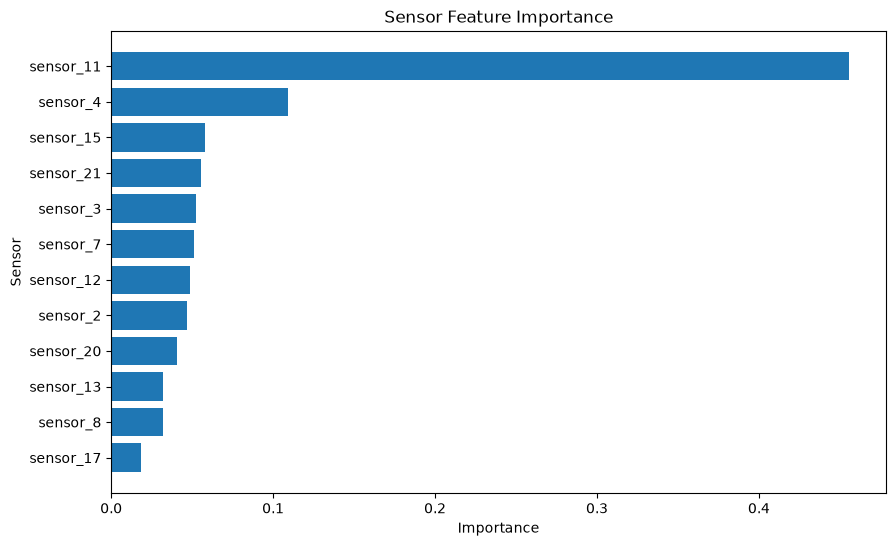

In [22]:
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["sensor"],
    feature_importance["importance"]
)

plt.xlabel("Importance")
plt.ylabel("Sensor")
plt.title("Sensor Feature Importance")
plt.gca().invert_yaxis()

plt.show()

In [23]:
import joblib
import os

os.makedirs("../models", exist_ok=True)

joblib.dump(model, "../models/rul_model.pkl")

joblib.dump(selected_sensors, "../models/selected_sensors.pkl")

print("Model saved successfully!")

Model saved successfully!


In [24]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Predictions on our held-out test data
y_pred = model.predict(X_test)

# Evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Model Evaluation")
print("----------------")
print(f"MAE  : {mae:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"R²   : {r2:.4f}")

Model Evaluation
----------------
MAE  : 29.57
RMSE : 39.07
R²   : 0.6458


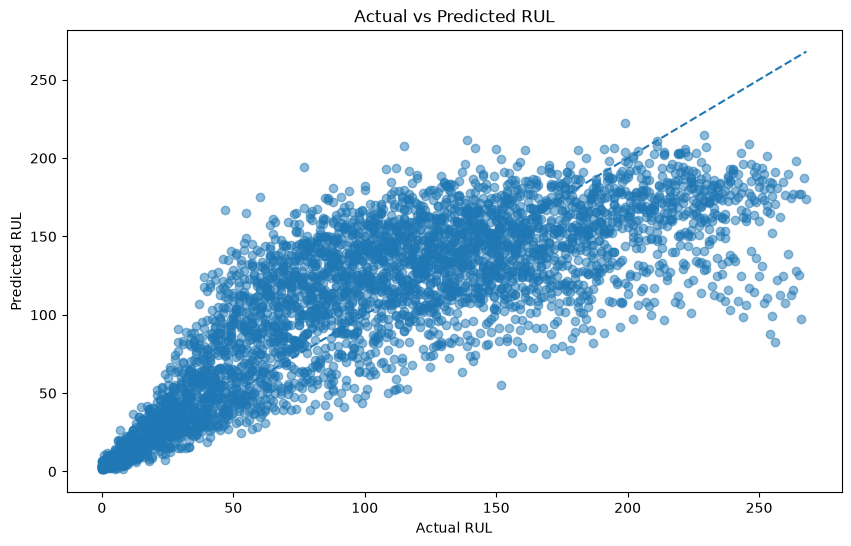

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(y_test, y_pred, alpha=0.5)

# Perfect prediction line
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual RUL")
plt.ylabel("Predicted RUL")
plt.title("Actual vs Predicted RUL")

plt.show()

In [26]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Model Evaluation")
print("----------------")
print(f"MAE  : {mae:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"R²   : {r2:.4f}")

Model Evaluation
----------------
MAE  : 29.57
RMSE : 39.07
R²   : 0.6458


In [27]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )
}

results = []

for name, model_test in models.items():

    print(f"Training {name}...")

    model_test.fit(X_train, y_train)

    predictions = model_test.predict(X_test)

    mae_test = mean_absolute_error(y_test, predictions)
    rmse_test = np.sqrt(mean_squared_error(y_test, predictions))
    r2_test = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "MAE": mae_test,
        "RMSE": rmse_test,
        "R2": r2_test
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values("MAE")

print("\nModel Comparison")
print("================")
print(results_df)

Training Random Forest...
Training Extra Trees...
Training Gradient Boosting...

Model Comparison
               Model        MAE       RMSE        R2
2  Gradient Boosting  29.193206  38.677499  0.652926
1        Extra Trees  29.558265  39.097054  0.645355
0      Random Forest  29.573780  39.074360  0.645767


In [28]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators": [100, 200, 300],
    "learning_rate": [0.03, 0.05, 0.1],
    "max_depth": [2, 3, 4],
    "min_samples_leaf": [2, 5, 10]
}

gb = GradientBoostingRegressor(random_state=42)

grid_search = GridSearchCV(
    estimator=gb,
    param_grid=param_grid,
    scoring="neg_mean_absolute_error",
    cv=3,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest CV MAE:")
print(-grid_search.best_score_)

Fitting 3 folds for each of 81 candidates, totalling 243 fits
Best Parameters:
{'learning_rate': 0.03, 'max_depth': 4, 'min_samples_leaf': 10, 'n_estimators': 300}

Best CV MAE:
34.671908505908284


In [29]:
# Test the tuned Gradient Boosting model

best_model = grid_search.best_estimator_

y_pred_tuned = best_model.predict(X_test)

mae_tuned = mean_absolute_error(y_test, y_pred_tuned)
rmse_tuned = np.sqrt(mean_squared_error(y_test, y_pred_tuned))
r2_tuned = r2_score(y_test, y_pred_tuned)

print("Tuned Gradient Boosting Evaluation")
print("----------------------------------")
print(f"MAE  : {mae_tuned:.2f}")
print(f"RMSE : {rmse_tuned:.2f}")
print(f"R²   : {r2_tuned:.4f}")

Tuned Gradient Boosting Evaluation
----------------------------------
MAE  : 29.02
RMSE : 38.64
R²   : 0.6537


In [30]:
import joblib

MODEL_PATH = "../models/rul_model.pkl"

joblib.dump(best_model, MODEL_PATH)

print("Tuned model saved successfully!")
print("Path:", MODEL_PATH)

Tuned model saved successfully!
Path: ../models/rul_model.pkl


In [31]:
import joblib

# Save the tuned Gradient Boosting model
joblib.dump(best_model, "../models/rul_model.pkl")

print("Tuned model saved successfully!")

Tuned model saved successfully!


In [32]:
print("Selected sensors:")
print(selected_sensors)

print("\nSensor ranges:")
print(X_train[selected_sensors].min())

print("\nSensor maximums:")
print(X_train[selected_sensors].max())

Selected sensors:
['sensor_11', 'sensor_4', 'sensor_12', 'sensor_7', 'sensor_15', 'sensor_21', 'sensor_20', 'sensor_2', 'sensor_17', 'sensor_3', 'sensor_8', 'sensor_13']

Sensor ranges:
sensor_11      46.8500
sensor_4     1385.1900
sensor_12     518.6900
sensor_7      549.8500
sensor_15       8.3279
sensor_21      22.8942
sensor_20      38.1400
sensor_2      641.2100
sensor_17     388.0000
sensor_3     1571.0400
sensor_8     2387.9000
sensor_13    2387.8800
dtype: float64

Sensor maximums:
sensor_11      48.5200
sensor_4     1441.4900
sensor_12     523.3800
sensor_7      556.0600
sensor_15       8.5848
sensor_21      23.6184
sensor_20      39.4300
sensor_2      644.5300
sensor_17     400.0000
sensor_3     1616.9100
sensor_8     2388.5600
sensor_13    2388.5600
dtype: float64
